<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/info_07_productores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import os
import pandas as pd
os.chdir('/content/drive/MyDrive/a_SENAMHI/OUT/')
!ls


base_final.csv	     comercio.dta    informacion.dta  top_regions.csv
caracteristicas.dta  coord_prod.csv  mq_eq.dta	      vbpagri.dta
caratulas.dta	     costos.dta      sf.dta
cofert.dta	     edu.dta	     supag.dta


In [2]:
df = pd.read_csv('base_final.csv', low_memory=False)

In [3]:
### nos quedamos con observaciones validas para info_5 y t_vbpagri

df_val=df.loc[(df.info_5.notna()) & (df.t_vbpagri.notna()) ].copy()

In [4]:
columns_to_fill = df_val.filter(regex=r'maq|equ|t_comprador|t_destino').columns
df_val[columns_to_fill] = df_val[columns_to_fill].fillna(0)

In [5]:
df_val['t_ingagri'] = (df_val.t_vbpagri - df_val.cost_tot).astype(float)

In [6]:
# Create dummy variables for REGION, dropping the first category to avoid multicollinearity
region_dummies = pd.get_dummies(df_val['REGION'], prefix='region', drop_first=True, dtype=float)
year_dummies = pd.get_dummies(df_val['ANIO'], prefix='year', drop_first=True, dtype=float)

# Join both region and year dummies back to our main enterprise dataframe as a list
df_val = df_val.join([region_dummies, year_dummies])


In [7]:
## Convertimos algunas variables a logaritmos

import numpy as np
ll=['ingagri', 'vbpagri', 'supcose', 'supag']
for dd in ll:
  # Using np.maximum(0, ...) to guarantee that the input to log1p is non-negative and avoid warnings
  df_val['log_'+dd] = np.log1p(df_val['t_'+dd])

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [8]:
## excluimos cuando ingreso neto agrario es negativo
df_val.loc[df_val.log_ingagri<0, 'log_ingagri'] = np.nan

In [9]:
df_val.filter(regex='log').describe().transpose()

,count,mean,std,min,25%,50%,75%,max
log_ingagri,47032.0,2.389077,1.689148,0.000000,1.090496,2.199444,3.380723,13.879978
log_vbpagri,97726.0,1.729344,1.806384,0.000000,0.000000,1.269761,2.903617,13.993067
log_supcose,97726.0,1.084367,1.014395,0.000300,0.357674,0.774727,1.504077,9.924872
log_supag,97726.0,1.749845,1.189516,0.001998,0.875052,1.504077,2.351375,10.757924


In [10]:
!pip install -q linearmodels
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

# 1. Create separate DataFrames for Empresas and Productores with explicit copies
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

# 2. Define independent variables lists
region_cols = ['region_Sierra', 'region_Selva']
year_cols = ['year_2024', 'year_2025']

# Note: based on previous cell edits, the column name is t_usoequ (or t_usoequip/t_usoequ depending on data)
# Let's dynamically find the correct usage column name for equipment
# usoequ_col = 't_usoequ' if 't_usoequ' in df_val.columns else 't_usoequip'

vars_common = ['info_5', 'log_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_destino3', 't_credito']

vars_pro = vars_common + ['t_jhedu', 't_jhedad', 't_jhmujer','t_exper'] + region_cols + year_cols

# Clean missing values for each model subset specifically

model_vars_pro = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro
base_pro = df_pro.dropna(subset=model_vars_pro).copy()

# Add constants explicitly for IV estimation
base_pro['const'] = 1.0

# --- PRODUCTORES MODEL ---
print("\n\n=== PRODUCTORES (INDIVIDUAL PRODUCERS) ===")
# Weighted OLS using WLS
formula_pro = f"log_vbpagri ~ {' + '.join(vars_pro)}"
wls_pro = smf.wls(formula_pro, data=base_pro,
                  weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='HC1')
print(wls_pro.summary())

# IV-2SLS Endogeneity Test
exog_pro = ['const'] + [v for v in vars_pro if v != 'info_5']
iv_pro = IV2SLS(dependent=base_pro['log_vbpagri'],
                 exog=base_pro[exog_pro],
                 endog=base_pro['info_5'],
                 instruments=base_pro['neces_AGROCLIM'],
                 weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print("\n--- Endogeneity Test (Productores) ---")
print(iv_pro.wu_hausman())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 26.7 MB/s eta 0:00:00


=== PRODUCTORES (INDIVIDUAL PRODUCERS) ===
                            WLS Regression Results                            
Dep. Variable:            log_vbpagri   R-squared:                       0.542
Model:                            WLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     1271.
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        09:38:41   Log-Likelihood:            -2.2411e+05
No. Observations:               95499   AIC:                         4.483e+05
Df Residuals:                   95483   BIC:                         4.484e+05
Df Model:                          15                                         
Covariance Type:                  HC1                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
------

In [11]:
# Estimate and print the detailed IV-2SLS model for producers
iv_model = IV2SLS(
    dependent=base_pro['log_vbpagri'],
    exog=base_pro[exog_pro],
    endog=base_pro['info_5'],
    instruments=base_pro['neces_AGROCLIM'],
    weights=base_pro['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print("=== IV-2SLS REGRESSION RESULTS (PRODUCTORES) ===")
print(iv_model.summary)


=== IV-2SLS REGRESSION RESULTS (PRODUCTORES) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:            log_vbpagri   R-squared:                      0.5253
Estimator:                    IV-2SLS   Adj. R-squared:                 0.5252
No. Observations:               95499   F-statistic:                 1.784e+04
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        09:39:03   Distribution:                 chi2(15)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const             1.5907     0.0686     23.191     0.0000      1.4562    

In [12]:
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# Define the variables list for the model in levels
# Replacing log_supcose with t_supcose
vars_pro_levels = [v if v != 'log_supcose' else 't_supcose' for v in vars_pro]

# Ensure all level model variables are non-null
model_vars_pro_levels = ['t_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro_levels
base_pro_levels = df_pro.dropna(subset=model_vars_pro_levels).copy()

# Add the constant term
base_pro_levels['const'] = 1.0

# Define exogenous and endogenous lists
exog_pro_levels = ['const'] + [v for v in vars_pro_levels if v != 'info_5']

# Estimate the IV-2SLS model in levels
iv_model_levels = IV2SLS(
    dependent=base_pro_levels['t_vbpagri'],
    exog=base_pro_levels[exog_pro_levels],
    endog=base_pro_levels['info_5'],
    instruments=base_pro_levels['neces_AGROCLIM'],
    weights=base_pro_levels['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print("=== IV-2SLS REGRESSION RESULTS IN LEVELS (PRODUCTORES) ===")
print(iv_model_levels.summary)

=== IV-2SLS REGRESSION RESULTS IN LEVELS (PRODUCTORES) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_vbpagri   R-squared:                      0.2791
Estimator:                    IV-2SLS   Adj. R-squared:                 0.2790
No. Observations:               95499   F-statistic:                    2039.4
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        09:40:49   Distribution:                 chi2(15)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const             33.310     3.6741     9.0662     0.0000      

In [13]:
import numpy as np
import pandas as pd

# Calculate percentiles and IQR for t_vbpagri
q25 = base_pro_levels['t_vbpagri'].quantile(0.25)
q75 = base_pro_levels['t_vbpagri'].quantile(0.75)
iqr = q75 - q25

# Define bounds for outliers
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# Find outliers
outliers = base_pro_levels[(base_pro_levels['t_vbpagri'] < lower_bound) | (base_pro_levels['t_vbpagri'] > upper_bound)]

print("=== OUTLIER ANALYSIS FOR t_vbpagri ===")
print(f"25th Percentile (Q1): {q25:.2f}")
print(f"75th Percentile (Q3): {q75:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Lower Bound for Outliers: {lower_bound:.2f}")
print(f"Upper Bound for Outliers: {upper_bound:.2f}")
print(f"Total Observations: {len(base_pro_levels)}")
print(f"Number of Outliers: {len(outliers)} ({len(outliers)/len(base_pro_levels)*100:.2f}% of data)")

# Display descriptive statistics of the outliers
print("\n=== Descriptive Statistics of Outliers ===")
display(outliers['t_vbpagri'].describe())

=== OUTLIER ANALYSIS FOR t_vbpagri ===
25th Percentile (Q1): 0.00
75th Percentile (Q3): 16.00
IQR: 16.00
Lower Bound for Outliers: -24.00
Upper Bound for Outliers: 40.00
Total Observations: 95499
Number of Outliers: 13057 (13.67% of data)

=== Descriptive Statistics of Outliers ===


,t_vbpagri
count,13057.000000
mean,154.109347
std,257.186929
min,40.002000
25%,56.000000
50%,85.350000
75%,152.740000
max,7076.588000


In [14]:
from linearmodels.iv import IV2SLS

# Filter the dataset to exclude outliers (t_vbpagri <= 40)
base_pro_levels_no_outliers = base_pro_levels[base_pro_levels['t_vbpagri'] <= 40.0].copy()

# Re-estimate the IV-2SLS model in levels without outliers
iv_model_levels_clean = IV2SLS(
    dependent=base_pro_levels_no_outliers['t_vbpagri'],
    exog=base_pro_levels_no_outliers[exog_pro_levels],
    endog=base_pro_levels_no_outliers['info_5'],
    instruments=base_pro_levels_no_outliers['neces_AGROCLIM'],
    weights=base_pro_levels_no_outliers['FACTOR_PRODUCTOR']
).fit(cov_type='robust')

print("=== IV-2SLS REGRESSION RESULTS IN LEVELS (WITHOUT OUTLIERS: t_vbpagri <= 40) ===")
print(f"New Sample Size: {len(base_pro_levels_no_outliers)} (Excluded {len(base_pro_levels) - len(base_pro_levels_no_outliers)} observations)")
print(iv_model_levels_clean.summary)

=== IV-2SLS REGRESSION RESULTS IN LEVELS (WITHOUT OUTLIERS: t_vbpagri <= 40) ===
New Sample Size: 82442 (Excluded 13057 observations)
                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_vbpagri   R-squared:                      0.2698
Estimator:                    IV-2SLS   Adj. R-squared:                 0.2697
No. Observations:               82442   F-statistic:                    2940.5
Date:                Thu, Oct 22 2026   P-value (F-stat)                0.0000
Time:                        09:44:10   Distribution:                 chi2(15)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
----------------------------------------------------------------------

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from linearmodels.iv import IV2SLS

# P102_N is the name of the crop in the ENA dataset
crop_column = 't_cultprinc'

if crop_column in base_pro.columns:
    top_10_crops = base_pro[crop_column].dropna().value_counts().head(10).index.tolist()
    print(f"Top 10 Crops based on 'P102_N':\n{top_10_crops}")
else:
    print(f"Column '{crop_column}' not found. Let's find other columns:")
    print([c for c in base_pro.columns if 'P10' in c])

Top 10 Crops based on 'P102_N':
['PASTO', 'MAIZ AMILACEO', 'ALFALFA', 'PAPA BLANCA', 'AVENA', 'ARROZ', 'MAIZ AMARILLO', 'PALTO', 'CAFE', 'PAPA NATIVA']


In [31]:
results_list = []

if 'top_10_crops' in globals() or 'top_10_crops' in locals():
    for crop in top_10_crops:
        crop_sub = base_pro[base_pro[crop_column] == crop].copy()

        # Filter out control variables that do not vary within this crop's subset
        clean_exog_pro = ['const']
        for var in exog_pro:
            if var != 'const':
                if crop_sub[var].nunique() > 1:
                    clean_exog_pro.append(var)

        if len(crop_sub) >= 100:
            try:
                iv_crop = IV2SLS(
                    dependent=crop_sub['log_vbpagri'],
                    exog=crop_sub[clean_exog_pro],
                    endog=crop_sub['info_5'],
                    instruments=crop_sub['neces_AGROCLIM'],
                    weights=crop_sub['FACTOR_PRODUCTOR']
                ).fit(cov_type='robust')

                coef = iv_crop.params['info_5']
                std_err = iv_crop.std_errors['info_5']
                ci_lower = iv_crop.conf_int().loc['info_5', 'lower']
                ci_upper = iv_crop.conf_int().loc['info_5', 'upper']
                p_val = iv_crop.pvalues['info_5']

                results_list.append({
                    'crop': str(crop),
                    'coefficient': coef,
                    'std_err': std_err,
                    'ci_lower': ci_lower,
                    'ci_upper': ci_upper,
                    'p_value': p_val,
                    'observations': len(crop_sub)
                })
            except Exception as e:
                print(f"Could not fit model for crop '{crop}': {e}")
        else:
            print(f"Skipping crop '{crop}' due to insufficient observations ({len(crop_sub)})")

df_results = pd.DataFrame(results_list)
display(df_results)

,crop,coefficient,std_err,ci_lower,ci_upper,p_value,observations
0,PASTO,0.169610,0.514206,-0.838215,1.177436,0.741514,10212
1,MAIZ AMILACEO,0.041256,0.156118,-0.264730,0.347241,0.791579,9268
2,ALFALFA,0.641668,0.627099,-0.587423,1.870760,0.306197,8988
3,PAPA BLANCA,0.213681,0.208815,-0.195589,0.622950,0.306165,5836
4,AVENA,-1.218785,1.145629,-3.464177,1.026607,0.287394,5113
5,ARROZ,0.482483,0.500134,-0.497762,1.462728,0.334692,3574
6,MAIZ AMARILLO,1.197333,0.678701,-0.132898,2.527563,0.077706,3558
7,PALTO,-2.148311,1.236547,-4.571898,0.275276,0.082326,3527
8,CAFE,-0.034743,0.490651,-0.996402,0.926916,0.943549,3490
9,PAPA NATIVA,-0.318354,0.334377,-0.973721,0.337014,0.341057,3323


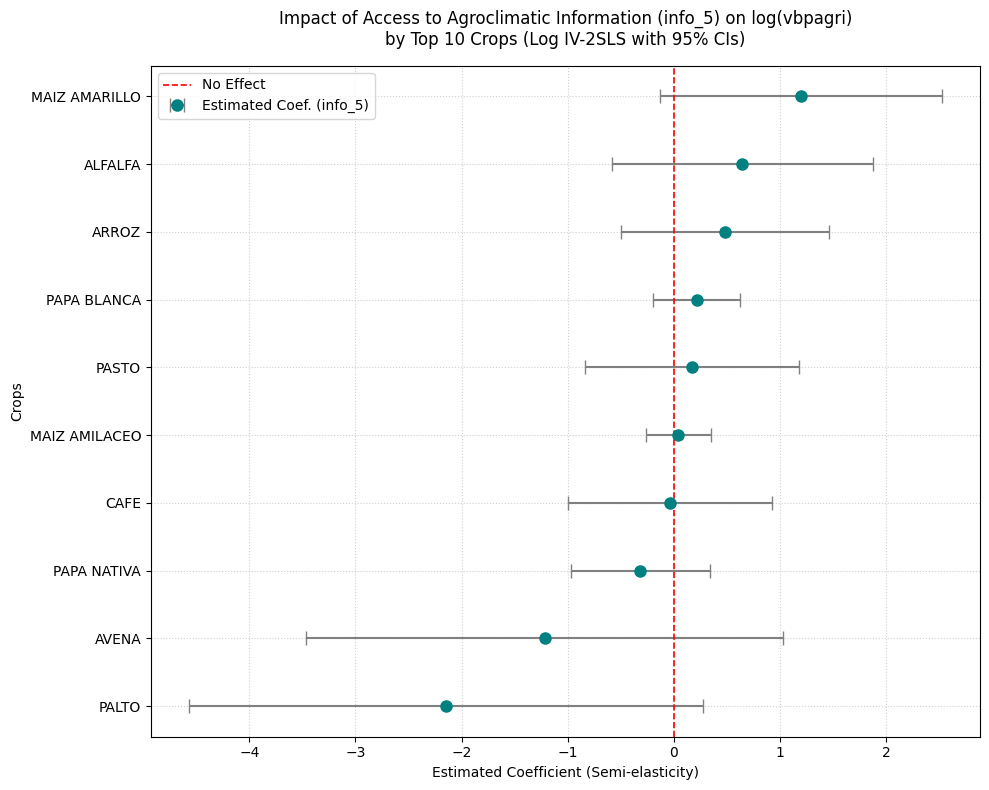

In [32]:
import matplotlib.pyplot as plt

if 'df_results' in globals() and not df_results.empty:
    # Sort results for visual order
    df_results_sorted = df_results.sort_values(by='coefficient', ascending=True)

    plt.figure(figsize=(10, 8))
    # Plot coefficients with error bars representing 95% Confidence Intervals
    plt.errorbar(
        x=df_results_sorted['coefficient'],
        y=df_results_sorted['crop'],
        xerr=[df_results_sorted['coefficient'] - df_results_sorted['ci_lower'], df_results_sorted['ci_upper'] - df_results_sorted['coefficient']],
        fmt='o',
        color='teal',
        ecolor='gray',
        capsize=5,
        markersize=8,
        label='Estimated Coef. (info_5)'
    )

    plt.axvline(x=0, color='red', linestyle='--', linewidth=1.2, label='No Effect')
    plt.title("Impact of Access to Agroclimatic Information (info_5) on log(vbpagri)\nby Top 10 Crops (Log IV-2SLS with 95% CIs)", fontsize=12, pad=15)
    plt.xlabel("Estimated Coefficient (Semi-elasticity)", fontsize=10)
    plt.ylabel("Crops", fontsize=10)
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("No results to plot. Please make sure the previous blocks ran successfully and generated data.")